# Extract nuclear regions in Tiff and calculate the overlapping size between two chromosome painting

In [1]:
import cv2
import numpy as np
import os
import random
import pandas as pd
import tifffile as tiff
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from skimage import filters, measure, morphology, color
from skimage.morphology import disk, erosion
from skimage.morphology import convex_hull_image
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
from skimage.measure import regionprops
# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
def load_image_tifffile(path, channel):
    """ Load a specific channel from a multi-channel TIFF image using tifffile. """
    image = tiff.imread(path)
    if len(image.shape) == 3 and channel < image.shape[0]:  # Ensure channel index is valid
        return image[channel]
    else:
        raise IndexError(f"Channel {channel} is out of bounds for image with shape {image.shape}")

In [2]:
def extract_nuclear_morphology(image):
    """ Extract nuclear morphology from an image. """
    # Convert to grayscale
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    
    # Enhance contrast with histogram equalization
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    
    # Compute threshold for nuclear envelope (bottom 5% intensity)
    nuclear_threshold = np.percentile(normalized_image.flatten(), 67)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=50000)  # Remove noise
    
    # Label connected components in the nuclear mask
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    return labeled_nuclei, num_labels

In [4]:
def calculate_overlap(region1, region2):
    """ Calculate the overlap between two binary masks. """
    overlap = np.logical_and(region1 == 255, region2 == 255)
    return np.sum(overlap)

In [5]:
def draw_contours(images, masks, titles, colors):
    """ Draw contours of nuclear mask, binary1, and binary2 in a single figure with three columns, using separate original images. """
    fig, axes = plt.subplots(1, 3, figsize=(6, 2))
    
    for ax, image, mask, title, color in zip(axes, images, masks, titles, colors):
        image_with_contours = image.copy()
        mask_uint8 = (mask * 255).astype(np.uint8)
        contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        for contour in contours:
            hull = cv2.convexHull(contour)
            cv2.drawContours(image_with_contours, [hull], -1, color, 2)
        
        ax.imshow(image_with_contours)
        ax.set_title(title)
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

In [6]:
#select the chr2 (no normalization), and chr11 (normalized intensity in nuclear from 0-1) chromosome painting territory
def preprocess_image_within_nuclear1(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))
    
    # Determine threshold value within nuclear region
    binary = (enhanced > 65).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    return binary

def preprocess_image_within_nuclear2(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    
    # Determine threshold value within nuclear region
    threshold_value = filters.threshold_otsu(enhanced[nuclear_mask > 0])
    binary = (enhanced > 75).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    return binary

In [ ]:
# Process multiple files in a directory
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/DE"
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

# Randomly select three images for threshold testing
sample_files = random.sample(tiff_files, min(3, len(tiff_files)))

print("Testing threshold on selected images:")
for file in sample_files:
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 5:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        image1 = load_image_tifffile(image_path, 2)
        image2 = load_image_tifffile(image_path, 4)
        image3 = load_image_tifffile(image_path, 3)
        
        # Extract nuclear morphology first
        nuclear_region, num_nuclei = extract_nuclear_morphology(image3)
        
        # Process pen-marked regions only within nuclear shape
        binary1 = preprocess_image_within_nuclear1(image1, nuclear_region)
        binary2 = preprocess_image_within_nuclear2(image2, nuclear_region)
        
        overlap_size = calculate_overlap(binary1, binary2)
        pixels_in_channel1 = np.sum(binary1 > 0)
        pixels_in_channel2 = np.sum(binary2 > 0)
        pixels_in_nuclear = np.sum(nuclear_region > 0)
        
        results.append([os.path.splitext(file)[0], overlap_size, pixels_in_channel1, pixels_in_channel2,pixels_in_nuclear])
        print(f"{file}: Overlap: {overlap_size}, Ch1 Pixels: {pixels_in_channel1}, Ch2 Pixels: {pixels_in_channel2}, Nuclear Pixels: {pixels_in_nuclear}")
        
        # Draw nuclear, binary1, and binary2 contours separately using their respective images
        draw_contours([image3, image1, image2], 
                      [nuclear_region, binary1, binary2], 
                      ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours"], 
                      [(255, 255, 255), (255, 0, 0), (0, 255, 0)])
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

# Convert results to a DataFrame and save as CSV
if results:
    output_df = pd.DataFrame(results, columns=["File", "Overlap Size", "Pixels in Channel 1", "Pixels in Channel 2", "Pixels in nuclear"])
else:
    print("No valid results found, skipping CSV save.")

In [ ]:
#Process multiple files in a directory (can set different threshold and save them into different table to do comparing)
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/DE"
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

results = []

for file in tiff_files:
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 5:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        image1 = load_image_tifffile(image_path, 2)
        image2 = load_image_tifffile(image_path, 4)
        image3 = load_image_tifffile(image_path, 3)
        
        # Extract nuclear morphology first
        nuclear_region, num_nuclei = extract_nuclear_morphology(image3)
        
        # Process pen-marked regions only within nuclear shape
        binary1 = preprocess_image_within_nuclear1(image1, nuclear_region)
        binary2 = preprocess_image_within_nuclear2(image2, nuclear_region)
        
        overlap_size = calculate_overlap(binary1, binary2)
        pixels_in_channel1 = np.sum(binary1 > 0)
        pixels_in_channel2 = np.sum(binary2 > 0)
        pixels_in_nuclear = np.sum(nuclear_region > 0)
        
        results.append([os.path.splitext(file)[0], overlap_size, pixels_in_channel1, pixels_in_channel2, pixels_in_nuclear])
        print(f"{file}: Overlap: {overlap_size}, Ch1 Pixels: {pixels_in_channel1}, Ch2 Pixels: {pixels_in_channel2}, Nuclear Pixels: {pixels_in_nuclear}")
        
        # Draw nuclear, binary1, and binary2 contours separately using their respective images
        draw_contours([image3, image1, image2], 
                      [nuclear_region, binary1, binary2], 
                      ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours"], 
                      [(255, 255, 255), (255, 0, 0), (0, 255, 0)])       
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

# Convert results to a DataFrame and save as CSV
if results:
    output_df2 = pd.DataFrame(results, columns=["File", "Overlap Size", "Pixels in Channel 1", "Pixels in Channel 2","Pixels in nuclear"])
    output_df2.to_csv(os.path.join(data_dir, "overlap_results_threshold2.csv"), index=False)
    print("Results saved to overlap_results.csv.")
else:
    print("No valid results found, skipping CSV save.")

In [103]:
output_df2

,File,Overlap Size,Pixels in Channel 1,Pixels in Channel 2,Pixels in nuclear
0,Series015_MIP,24,5844,22401,254503
1,Series023_MIP,167,5405,19044,300382
2,Series014_MIP,1808,3872,47739,319667
3,Series022_MIP,1033,8558,12681,335773
4,DE_chr2_550_chr11_488_chr2_153_cy5_MIP,8758,31868,63305,303400
5,Series020_MIP,614,6120,18329,320017
6,Series006_MIP,8494,23694,63114,296300
7,Series016_MIP,0,18464,6409,339817
8,Series029_MIP,1017,18598,18867,336231
9,Series007_MIP,0,2953,30947,339798


In [110]:
#set the threshold for HB
#select the chr2 (no normalization), and chr11 (normalized intensity in nuclear from 0-1) chromosome painting territory
def preprocess_image_within_nuclear1(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))
    
    # Determine threshold value within nuclear region
    binary = (enhanced > 70).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    return binary

def preprocess_image_within_nuclear2(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    
    # Determine threshold value within nuclear region
    threshold_value = filters.threshold_otsu(enhanced[nuclear_mask > 0])
    binary = (enhanced > 85).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    return binary

In [ ]:
#Process multiple files in a directory (can set different threshold and save them into different table to do comparing)
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/HB"
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

results = []

for file in tiff_files:
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 5:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        image1 = load_image_tifffile(image_path, 2)
        image2 = load_image_tifffile(image_path, 4)
        image3 = load_image_tifffile(image_path, 3)
        
        # Extract nuclear morphology first
        nuclear_region, num_nuclei = extract_nuclear_morphology(image3)
        
        # Process pen-marked regions only within nuclear shape
        binary1 = preprocess_image_within_nuclear1(image1, nuclear_region)
        binary2 = preprocess_image_within_nuclear2(image2, nuclear_region)
        
        overlap_size = calculate_overlap(binary1, binary2)
        pixels_in_channel1 = np.sum(binary1 > 0)
        pixels_in_channel2 = np.sum(binary2 > 0)
        pixels_in_nuclear = np.sum(nuclear_region > 0)
        
        results.append([os.path.splitext(file)[0], overlap_size, pixels_in_channel1, pixels_in_channel2, pixels_in_nuclear])
        print(f"{file}: Overlap: {overlap_size}, Ch1 Pixels: {pixels_in_channel1}, Ch2 Pixels: {pixels_in_channel2}, Nuclear Pixels: {pixels_in_nuclear}")
        
        # Draw nuclear, binary1, and binary2 contours separately using their respective images
        draw_contours([image3, image1, image2], 
                      [nuclear_region, binary1, binary2], 
                      ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours"], 
                      [(255, 255, 255), (255, 0, 0), (0, 255, 0)])       
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

# Convert results to a DataFrame and save as CSV
if results:
    output_df2 = pd.DataFrame(results, columns=["File", "Overlap Size", "Pixels in Channel 1", "Pixels in Channel 2","Pixels in nuclear"])
    output_df2.to_csv(os.path.join(data_dir, "overlap_results_threshold2.csv"), index=False)
    print("Results saved to overlap_results.csv.")
else:
    print("No valid results found, skipping CSV save.")

In [112]:
output_df2

,File,Overlap Size,Pixels in Channel 1,Pixels in Channel 2,Pixels in nuclear
0,Series048_MIP,0,27180,20527,307244
1,Series058_MIP,161,22591,18106,332477
2,Series033_MIP,0,21176,17595,340992
3,Series051_MIP,0,33558,15396,327691
4,Series041_MIP,2555,19899,23044,342744
5,Series032_MIP,4011,30622,43465,344859
6,Series040_MIP,380,11927,46170,313905
7,Series050_MIP,10,36142,31905,342872
8,Series059_MIP,0,4155,9552,341159
9,Series049_MIP,3714,57232,38751,344828


In [20]:
#set the parameters for H1: 1. min_size = 100, 2. channel 4 did pixel normalization in nuclear
#select the chr2 (no normalization), and chr11 (normalized intensity in nuclear from 0-1) chromosome painting territory
def preprocess_image_within_nuclear1(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))
    
    # Determine threshold value within nuclear region
    binary = (enhanced > 58).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=100).astype(np.uint8) * 255  # Remove noise
    
    return binary

def preprocess_image_within_nuclear2(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))
    
    # Determine threshold value within nuclear region
    binary = (enhanced > 88).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=100).astype(np.uint8) * 255  # Remove noise
    
    return binary

In [ ]:
#Process multiple files in a directory (can set different threshold and save them into different table to do comparing)
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/H1"
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

results = []

for file in tiff_files:
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 5:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        image1 = load_image_tifffile(image_path, 2)
        image2 = load_image_tifffile(image_path, 4)
        image3 = load_image_tifffile(image_path, 3)
        
        # Extract nuclear morphology first
        nuclear_region, num_nuclei = extract_nuclear_morphology(image3)
        
        # Process pen-marked regions only within nuclear shape
        binary1 = preprocess_image_within_nuclear1(image1, nuclear_region)
        binary2 = preprocess_image_within_nuclear2(image2, nuclear_region)
        
        overlap_size = calculate_overlap(binary1, binary2)
        pixels_in_channel1 = np.sum(binary1 > 0)
        pixels_in_channel2 = np.sum(binary2 > 0)
        pixels_in_nuclear = np.sum(nuclear_region > 0)
        
        results.append([os.path.splitext(file)[0], overlap_size, pixels_in_channel1, pixels_in_channel2, pixels_in_nuclear])
        print(f"{file}: Overlap: {overlap_size}, Ch1 Pixels: {pixels_in_channel1}, Ch2 Pixels: {pixels_in_channel2}, Nuclear Pixels: {pixels_in_nuclear}")
        
        # Draw nuclear, binary1, and binary2 contours separately using their respective images
        draw_contours([image3, image1, image2], 
                      [nuclear_region, binary1, binary2], 
                      ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours"], 
                      [(255, 255, 255), (255, 0, 0), (0, 255, 0)])       
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

# Convert results to a DataFrame and save as CSV
if results:
    output_df2 = pd.DataFrame(results, columns=["File", "Overlap Size", "Pixels in Channel 1", "Pixels in Channel 2","Pixels in nuclear"])
    output_df2.to_csv(os.path.join(data_dir, "overlap_results_threshold2.csv"), index=False)
    print("Results saved to overlap_results.csv.")
else:
    print("No valid results found, skipping CSV save.")

In [22]:
output_df2.head(50)

,File,Overlap Size,Pixels in Channel 1,Pixels in Channel 2,Pixels in nuclear
0,H1_chr2_550_chr11_488_chr2_153_cy5_16_MIP,7028,27623,90626,279338
1,H1_chr2_550_chr11_488_chr2_153_cy5_4_MIP,34718,95075,86609,282838
2,H1_chr2_550_chr11_488_chr2_157_647_Position 20...,2169,8993,59286,249922
3,H1_chr2_550_chr11_488_chr2_157_647_Position 30...,3804,11897,104444,339580
4,H1_chr2_550_chr11_488_chr2_153_cy5_39_MIP,7758,9412,132332,342304
5,H1_chr2_550_chr11_488_chr2_153_cy5_29_MIP,4291,25757,38444,273923
6,H1_chr2_550_chr11_488_chr2_157_647_Position 9_MIP,11231,35987,101682,319596
7,H1_chr2_550_chr11_488_chr2_157_647_Position 42...,15125,24012,168758,332584
8,H1_chr2_550_chr11_488_chr2_157_647_Position 16...,1423,2716,52117,208397
9,H1_chr2_550_chr11_488_chr2_153_cy5_42_MIP,20805,26643,239094,341418


In [39]:
#iHep/mHep needs to remove the nucleous regions
def extract_nuclear_morphology_removeplot_nucleolus(image):
    """ Extract nuclear morphology and remove nucleolus regions. """
    # Convert to grayscale
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    
    # Enhance contrast with histogram equalization
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    
    # Compute threshold for nuclear envelope (top 10% intensity)
    nuclear_threshold = np.percentile(normalized_image.flatten(), 70)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=50000)  # Remove noise
    
    # Label connected components in the nuclear mask
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    # Process each labeled nucleus separately
    for region in measure.regionprops(labeled_nuclei):
        if region.area < 1000:
            continue
        
        single_nucleus_mask = (labeled_nuclei == region.label)
        nuclear_convex_hull = convex_hull_image(single_nucleus_mask)
        
        # Compute erosion of the nuclear convex hull to exclude peripheral regions
        nuclear_area_pixels = np.sum(nuclear_convex_hull)
        equivalent_radius = np.sqrt(nuclear_area_pixels / np.pi)
        erosion_size = max(1, int(0.1 * equivalent_radius))
        selem = disk(erosion_size)
        eroded_nuclear_convex_hull = erosion(nuclear_convex_hull, selem)
        
        # Normalize the pixel intensities within the eroded nuclear convex hull
        masked_normalized_image = normalized_image * eroded_nuclear_convex_hull
        non_zero_pixels = masked_normalized_image[eroded_nuclear_convex_hull > 0]
        if non_zero_pixels.size > 0:
            normalized_within_nucleus = (masked_normalized_image - masked_normalized_image.min()) / (masked_normalized_image.max() - masked_normalized_image.min())
        else:
            normalized_within_nucleus = masked_normalized_image  # Fallback in case of an empty mask
        
        # Identify nucleolus regions within the normalized eroded nuclear convex hull area
        nucleolus_region = normalized_within_nucleus * eroded_nuclear_convex_hull
        nucleolus_pixels = nucleolus_region[nucleolus_region > 0]
        
        if len(nucleolus_pixels) > 0:
            nucleolus_threshold = np.percentile(nucleolus_pixels, 15)  # Bottom 13% intensity
        else:
            nucleolus_threshold = 0
        
        nucleolus_mask = (nucleolus_region <= nucleolus_threshold) & (nucleolus_region > 0)
        nucleolus_mask = morphology.remove_small_objects(nucleolus_mask, min_size=250)  # Remove false nucleolus signal
        
        # Remove nucleolus regions from labeled nuclei
        labeled_nuclei[nucleolus_mask > 0] = 0
    
            # Find contours for the single nucleus and nucleolus
        single_nucleus_uint8 = (single_nucleus_mask * 255).astype(np.uint8)
        nucleolus_mask_uint8 = (nucleolus_mask * 255).astype(np.uint8)

        contours_nuclear, _ = cv2.findContours(single_nucleus_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contours_nucleolus, _ = cv2.findContours(nucleolus_mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # Draw contours on the original grayscale image
        image_with_contours = np.stack([gray_image] * 3, axis=-1) if len(image.shape) == 2 else image.copy()
        for contour in contours_nuclear:
            hull = cv2.convexHull(contour)
            cv2.drawContours(image_with_contours, [hull], -1, (0, 255, 0), 2)  # Nuclear envelope in green

        for contour in contours_nucleolus:
            hull = cv2.convexHull(contour)
            cv2.drawContours(image_with_contours, [hull], -1, (255, 0, 0), 2)  # Nucleolus in red

        # Display the results
        fig, ax = plt.subplots(1, 2, figsize=(3, 3))
        ax[0].imshow(gray_image, cmap='gray')
        ax[0].set_title("Original Image")

        ax[1].imshow(image_with_contours)
        ax[1].set_title("Nuclear and Nucleolus Contours")

        for a in ax:
            a.axis('off')

        plt.tight_layout()
        plt.show()
    
    return labeled_nuclei, num_labels

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


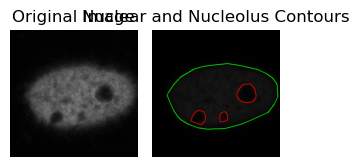

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


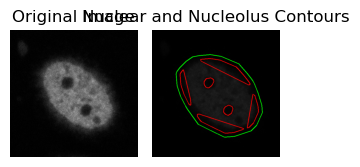

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


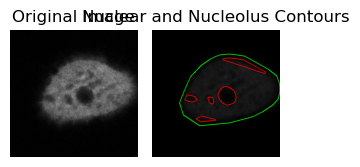

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


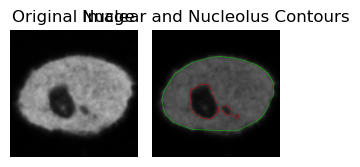

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


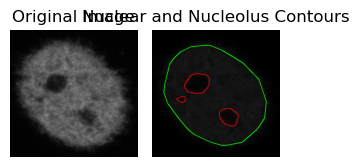

In [127]:
#Test nuclear_morplogy_extraction function is work. 
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/"
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

results = []

for file in tiff_files:
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 5:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        image3 = load_image_tifffile(image_path, 3)
        
        # Extract nuclear morphology first
        nuclear_region, num_nuclei = extract_nuclear_morphology_removeplot_nucleolus(image3)
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

In [7]:
def extract_nuclear_morphology(image):
    """ Extract nuclear morphology and remove nucleolus regions. """
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    nuclear_threshold = np.percentile(normalized_image.flatten(), 70)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=50000)
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    
    # Process each labeled nucleus separately
    for region in measure.regionprops(labeled_nuclei):
        if region.area < 1000:
            continue
        
        single_nucleus_mask = (labeled_nuclei == region.label)
        nuclear_convex_hull = convex_hull_image(single_nucleus_mask)
        
        # Compute erosion of the nuclear convex hull to exclude peripheral regions
        nuclear_area_pixels = np.sum(nuclear_convex_hull)
        equivalent_radius = np.sqrt(nuclear_area_pixels / np.pi)
        erosion_size = max(1, int(0.1 * equivalent_radius))
        selem = disk(erosion_size)
        eroded_nuclear_convex_hull = erosion(nuclear_convex_hull, selem)
        
        # Normalize the pixel intensities within the eroded nuclear convex hull
        masked_normalized_image = normalized_image * eroded_nuclear_convex_hull
        non_zero_pixels = masked_normalized_image[eroded_nuclear_convex_hull > 0]
        if non_zero_pixels.size > 0:
            normalized_within_nucleus = (masked_normalized_image - masked_normalized_image.min()) / (masked_normalized_image.max() - masked_normalized_image.min())
        else:
            normalized_within_nucleus = masked_normalized_image  # Fallback in case of an empty mask
        
        # Identify nucleolus regions within the normalized eroded nuclear convex hull area
        nucleolus_region = normalized_within_nucleus * eroded_nuclear_convex_hull
        nucleolus_pixels = nucleolus_region[nucleolus_region > 0]
        
        if len(nucleolus_pixels) > 0:
            nucleolus_threshold = np.percentile(nucleolus_pixels, 15)
        else:
            nucleolus_threshold = 0
        
        nucleolus_mask = (nucleolus_region <= nucleolus_threshold) & (nucleolus_region > 0)
        nucleolus_mask = morphology.remove_small_objects(nucleolus_mask, min_size=250)
        
        # Remove nucleolus regions from labeled nuclei
        labeled_nuclei[nucleolus_mask > 0] = 0
    
    return labeled_nuclei, num_labels
    """ Extract nuclear morphology and remove nucleolus regions. """
    gray_image = color.rgb2gray(image) if len(image.shape) == 3 else image / 255.0
    equalized_image = cv2.equalizeHist((gray_image * 255).astype(np.uint8))
    normalized_image = equalized_image / 255.0
    nuclear_threshold = np.percentile(normalized_image.flatten(), 70)
    nuclear_mask = normalized_image >= nuclear_threshold
    nuclear_mask = morphology.remove_small_objects(nuclear_mask, min_size=50000)
    labeled_nuclei, num_labels = measure.label(nuclear_mask, connectivity=2, return_num=True)
    return labeled_nuclei, num_labels

In [17]:
#select the chr2 (no normalization), and chr11 (normalized intensity in nuclear from 0-1) chromosome painting territory
def preprocess_image_within_nuclear1(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))
    
    # Determine threshold value within nuclear region
    binary = (enhanced > 75).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    return binary

def preprocess_image_within_nuclear2(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(gray)
    
    # Determine threshold value within nuclear region
    threshold_value = filters.threshold_otsu(enhanced[nuclear_mask > 0])
    binary = (enhanced > 95).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    return binary

In [ ]:
#Process multiple files in a directory (can set different threshold and save them into different table to do comparing)
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/iHep"
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

results = []

for file in tiff_files:
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 5:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        image1 = load_image_tifffile(image_path, 2)
        image2 = load_image_tifffile(image_path, 4)
        image3 = load_image_tifffile(image_path, 3)
        
        # Extract nuclear morphology first
        nuclear_region, num_nuclei = extract_nuclear_morphology(image3)
        
        # Process pen-marked regions only within nuclear shape
        binary1 = preprocess_image_within_nuclear1(image1, nuclear_region)
        binary2 = preprocess_image_within_nuclear2(image2, nuclear_region)
        
        overlap_size = calculate_overlap(binary1, binary2)
        pixels_in_channel1 = np.sum(binary1 > 0)
        pixels_in_channel2 = np.sum(binary2 > 0)
        pixels_in_nuclear = np.sum(nuclear_region > 0)
        
        results.append([os.path.splitext(file)[0], overlap_size, pixels_in_channel1, pixels_in_channel2, pixels_in_nuclear])
        print(f"{file}: Overlap: {overlap_size}, Ch1 Pixels: {pixels_in_channel1}, Ch2 Pixels: {pixels_in_channel2}, Nuclear Pixels: {pixels_in_nuclear}")
        
        # Draw nuclear, binary1, and binary2 contours separately using their respective images
        draw_contours([image3, image1, image2], 
                      [nuclear_region, binary1, binary2], 
                      ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours"], 
                      [(255, 255, 255), (255, 0, 0), (0, 255, 0)])       
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

# Convert results to a DataFrame and save as CSV
if results:
    output_df3 = pd.DataFrame(results, columns=["File", "Overlap Size", "Pixels in Channel 1", "Pixels in Channel 2","Pixels in nuclear"])
    output_df3.to_csv(os.path.join(data_dir, "overlap_results_threshold3.csv"), index=False)
    print("Results saved to overlap_results.csv.")
else:
    print("No valid results found, skipping CSV save.")

In [19]:
output_df3

,File,Overlap Size,Pixels in Channel 1,Pixels in Channel 2,Pixels in nuclear
0,Series077_MIP,0,13095,9436,295245
1,Series067_MIP,7001,17830,49210,1179844
2,iHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,2140,8123,74132
3,iHep_chr11_488_chr2_153_647_chr2_550_1_MIP,508,3194,3759,75030
4,Series083_MIP,0,6420,0,288954
5,iHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,2100,6929,68938
6,iHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,3038,4252,78276
7,iHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,196,5402,7536,76365
8,iHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,805,4431,6053,63337
9,iHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,521,6736,4588,73482


In [24]:
#select the chr2 (no normalization), and chr11 (normalized intensity in nuclear from 0-1) chromosome painting territory
def preprocess_image_within_nuclear1(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold for Channel 1 within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))
    
    # Determine threshold value within nuclear region
    binary = (enhanced > 77).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
    
    return binary

def preprocess_image_within_nuclear2(image, nuclear_mask):
    """ Enhance contrast and apply adaptive threshold within nuclear regions. """
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    gray = image.astype(np.uint8) * (nuclear_mask > 0)  # Apply nuclear mask
    
    # Normalize only within nuclear regions
    min_val = np.min(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 0
    max_val = np.max(gray[nuclear_mask > 0]) if np.any(nuclear_mask > 0) else 255
    normalized_image = np.zeros_like(gray, dtype=np.float32)
    if max_val > min_val:
        normalized_image[nuclear_mask > 0] = (gray[nuclear_mask > 0] - min_val) / (max_val - min_val)
    
    # Apply CLAHE (Contrast Limited Adaptive Histogram Equalization)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    enhanced = clahe.apply((normalized_image * 255).astype(np.uint8))
    
    # Determine threshold value within nuclear region
    binary = (enhanced > 97).astype(np.uint8) * 255
    binary = morphology.remove_small_objects(binary.astype(bool), min_size=1000).astype(np.uint8) * 255  # Remove noise
      
    return binary

In [ ]:
#Process multiple files in a directory (can set different threshold and save them into different table to do comparing)
data_dir = "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/mHep"
tiff_files = [f for f in os.listdir(data_dir) if f.endswith(".tif")]

results = []

for file in tiff_files:
    image_path = os.path.join(data_dir, file)
    try:
        # Load required channels using tifffile
        image = tiff.imread(image_path)
        if len(image.shape) < 3 or image.shape[0] < 5:
            print(f"Skipping {file}: Not enough channels ({image.shape})")
            continue

        image1 = load_image_tifffile(image_path, 2)
        image2 = load_image_tifffile(image_path, 4)
        image3 = load_image_tifffile(image_path, 3)
        
        # Extract nuclear morphology first
        nuclear_region, num_nuclei = extract_nuclear_morphology(image3)
        
        # Process pen-marked regions only within nuclear shape
        binary1 = preprocess_image_within_nuclear1(image1, nuclear_region)
        binary2 = preprocess_image_within_nuclear2(image2, nuclear_region)
        
        overlap_size = calculate_overlap(binary1, binary2)
        pixels_in_channel1 = np.sum(binary1 > 0)
        pixels_in_channel2 = np.sum(binary2 > 0)
        pixels_in_nuclear = np.sum(nuclear_region > 0)
        
        results.append([os.path.splitext(file)[0], overlap_size, pixels_in_channel1, pixels_in_channel2, pixels_in_nuclear])
        print(f"{file}: Overlap: {overlap_size}, Ch1 Pixels: {pixels_in_channel1}, Ch2 Pixels: {pixels_in_channel2}, Nuclear Pixels: {pixels_in_nuclear}")
        
        # Draw nuclear, binary1, and binary2 contours separately using their respective images
        draw_contours([image3, image1, image2], 
                      [nuclear_region, binary1, binary2], 
                      ["Nuclear Envelope Contours", "Channel 1 Contours", "Channel 2 Contours"], 
                      [(255, 255, 255), (255, 0, 0), (0, 255, 0)])       
        
    except Exception as e:
        print(f"Error processing {file}: {e}")

# Convert results to a DataFrame and save as CSV
if results:
    output_df3 = pd.DataFrame(results, columns=["File", "Overlap Size", "Pixels in Channel 1", "Pixels in Channel 2","Pixels in nuclear"])
    output_df3.to_csv(os.path.join(data_dir, "overlap_results_threshold3.csv"), index=False)
    print("Results saved to overlap_results.csv.")
else:
    print("No valid results found, skipping CSV save.")

In [26]:
output_df3

,File,Overlap Size,Pixels in Channel 1,Pixels in Channel 2,Pixels in nuclear
0,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,1155,8870,8611,72553
1,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,312,5161,6408,73517
2,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,1493,4645,9028,71787
3,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,4563,6347,72948
4,mHep_chr2_550_chr11_488_chr2_153_cy5_MIP,0,0,0,294655
5,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,8417,10710,75384
6,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,347,7817,8714,78361
7,Series082_MIP,1181,23749,17952,298763
8,Series092_MIP,0,0,51739,293637
9,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,4912,7421,70695


# organize all of table together and do statistics

In [2]:
# read the table from five different stage:
# Define file paths and corresponding stage names
stage_files = {
    "H1": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/H1/overlap_results_threshold2.csv",
    "DE": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/DE/overlap_results_threshold2.csv",
    "HB": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/HB/overlap_results_threshold2.csv",
    "iHep": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/iHep/overlap_results_threshold3.csv",
    "mHep": "/home/xiangru.huo-umw/scHiC/scripts/DNAfish_maximumtif/chromsome_territory/mHep/overlap_results_threshold3.csv",
}

# Define common column names
columns = ["File", "Overlap Size", "Pixels in Channel 1", "Pixels in Channel 2", "Pixels in nuclear"]

# List to store DataFrames
df_list = []

# Read each file, label stage, and store in list
for stage, file_path in stage_files.items():
    df = pd.read_csv(file_path, usecols=columns)
    df["Stage"] = stage  # Add stage column before concatenation
    df = df[(df["Pixels in Channel 1"] != 0) & (df["Pixels in Channel 2"] != 0)]  # Drop rows where either column is 0
    df_list.append(df)

# Concatenate all DataFrames
two_chromsomes_df = pd.concat(df_list, ignore_index=True)

In [3]:
two_chromsomes_df

,File,Overlap Size,Pixels in Channel 1,Pixels in Channel 2,Pixels in nuclear,Stage
0,H1_chr2_550_chr11_488_chr2_153_cy5_16_MIP,7028,27623,90626,279338,H1
1,H1_chr2_550_chr11_488_chr2_153_cy5_4_MIP,34718,95075,86609,282838,H1
2,H1_chr2_550_chr11_488_chr2_157_647_Position 20...,2169,8993,59286,249922,H1
3,H1_chr2_550_chr11_488_chr2_157_647_Position 30...,3804,11897,104444,339580,H1
4,H1_chr2_550_chr11_488_chr2_153_cy5_39_MIP,7758,9412,132332,342304,H1
...,...,...,...,...,...,...
238,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,6,4680,4663,71854,mHep
239,Series086_MIP,1578,6608,39213,285053,mHep
240,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,5985,1697,71584,mHep
241,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,5514,5966,79668,mHep


In [4]:
#calculation
two_chromsomes_df['Overlapsize/chr11'] = two_chromsomes_df['Overlap Size']/two_chromsomes_df['Pixels in Channel 1']
two_chromsomes_df['Overlapsize/chr2'] = two_chromsomes_df['Overlap Size']/two_chromsomes_df['Pixels in Channel 2']

two_chromsomes_df['chr11/nuclear'] = two_chromsomes_df['Pixels in Channel 1']/two_chromsomes_df['Pixels in nuclear']
two_chromsomes_df['chr2/nuclear'] = two_chromsomes_df['Pixels in Channel 2']/two_chromsomes_df['Pixels in nuclear']

two_chromsomes_df['Overlapsize/nuclear'] = two_chromsomes_df['Overlap Size']/two_chromsomes_df['Pixels in nuclear']
two_chromsomes_df

,File,Overlap Size,Pixels in Channel 1,Pixels in Channel 2,Pixels in nuclear,Stage,Overlapsize/chr11,Overlapsize/chr2,chr11/nuclear,chr2/nuclear,Overlapsize/nuclear
0,H1_chr2_550_chr11_488_chr2_153_cy5_16_MIP,7028,27623,90626,279338,H1,0.254426,0.077549,0.098887,0.324431,0.025159
1,H1_chr2_550_chr11_488_chr2_153_cy5_4_MIP,34718,95075,86609,282838,H1,0.365164,0.400859,0.336146,0.306214,0.122749
2,H1_chr2_550_chr11_488_chr2_157_647_Position 20...,2169,8993,59286,249922,H1,0.241188,0.036585,0.035983,0.237218,0.008679
3,H1_chr2_550_chr11_488_chr2_157_647_Position 30...,3804,11897,104444,339580,H1,0.319744,0.036421,0.035034,0.307568,0.011202
4,H1_chr2_550_chr11_488_chr2_153_cy5_39_MIP,7758,9412,132332,342304,H1,0.824267,0.058625,0.027496,0.386592,0.022664
...,...,...,...,...,...,...,...,...,...,...,...
238,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,6,4680,4663,71854,mHep,0.001282,0.001287,0.065132,0.064895,0.000084
239,Series086_MIP,1578,6608,39213,285053,mHep,0.238801,0.040242,0.023182,0.137564,0.005536
240,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,5985,1697,71584,mHep,0.000000,0.000000,0.083608,0.023706,0.000000
241,mHep_chr11_488_chr2_153_647_chr2_550_2_Positio...,0,5514,5966,79668,mHep,0.000000,0.000000,0.069212,0.074886,0.000000


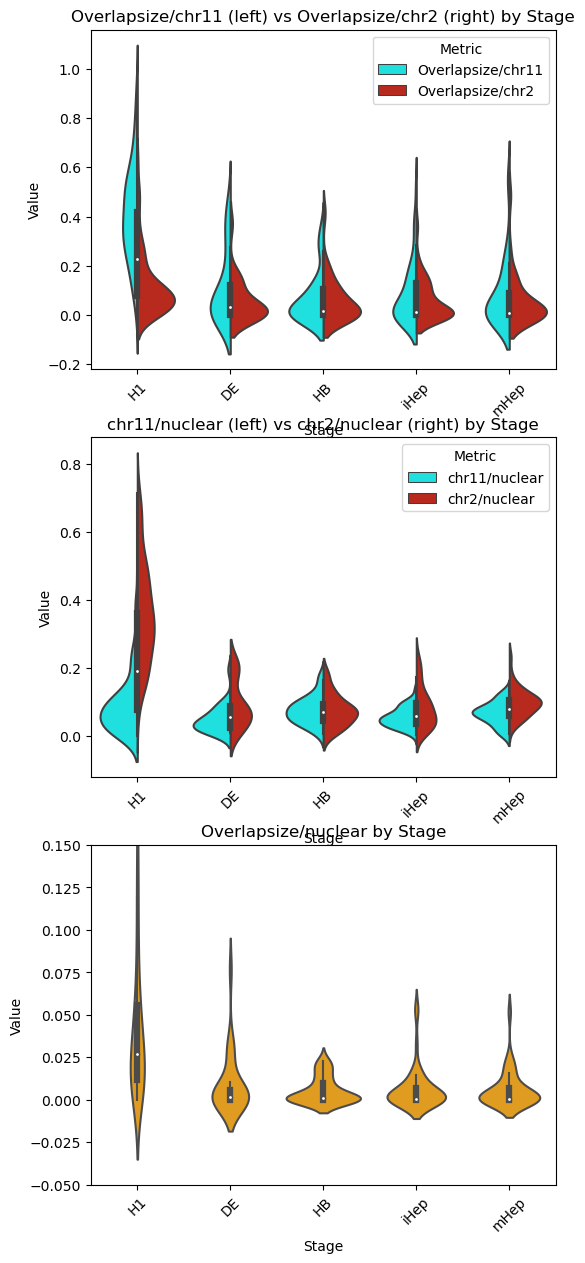

In [11]:
# Melt the DataFrames
df_top = two_chromsomes_df.melt(
    id_vars=["Stage"],
    value_vars=["Overlapsize/chr11", "Overlapsize/chr2"],
    var_name="Metric",
    value_name="Value"
)

df_bottom = two_chromsomes_df.melt(
    id_vars=["Stage"],
    value_vars=["chr11/nuclear", "chr2/nuclear"],
    var_name="Metric",
    value_name="Value"
)

df_nuclear = two_chromsomes_df.melt(
    id_vars=["Stage"],
    value_vars=["Overlapsize/nuclear"],
    var_name="Metric",
    value_name="Value"
)

# Create figure with 3 rows
fig, axes = plt.subplots(3, 1, figsize=(6, 15))

# Top plot
sns.violinplot(
    data=df_top,
    x="Stage",
    y="Value",
    hue="Metric",
    split=True,
    hue_order=["Overlapsize/chr11", "Overlapsize/chr2"],
    palette={"Overlapsize/chr11": "cyan", "Overlapsize/chr2": "#D21404"},
    ax=axes[0]
)
axes[0].set_title("Overlapsize/chr11 (left) vs Overlapsize/chr2 (right) by Stage")
axes[0].set_ylabel("Value")
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title="Metric")

# Middle plot
sns.violinplot(
    data=df_bottom,
    x="Stage",
    y="Value",
    hue="Metric",
    split=True,
    hue_order=["chr11/nuclear", "chr2/nuclear"],
    palette={"chr11/nuclear": "cyan", "chr2/nuclear": "#D21404"},
    ax=axes[1]
)
axes[1].set_title("chr11/nuclear (left) vs chr2/nuclear (right) by Stage")
axes[1].set_ylabel("Value")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title="Metric")

# Bottom plot (single metric, orange)
sns.violinplot(
    data=df_nuclear,
    x="Stage",
    y="Value",
    color="orange",   # single color for one metric
    ax=axes[2]
)
axes[2].set_title("Overlapsize/nuclear by Stage")
axes[2].set_ylabel("Value")
axes[2].set_ylim(-0.05, 0.15)
axes[2].tick_params(axis='x', rotation=45)


# Save the plot as a PDF with dpi=200
output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/Chromosome_intermingling.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()

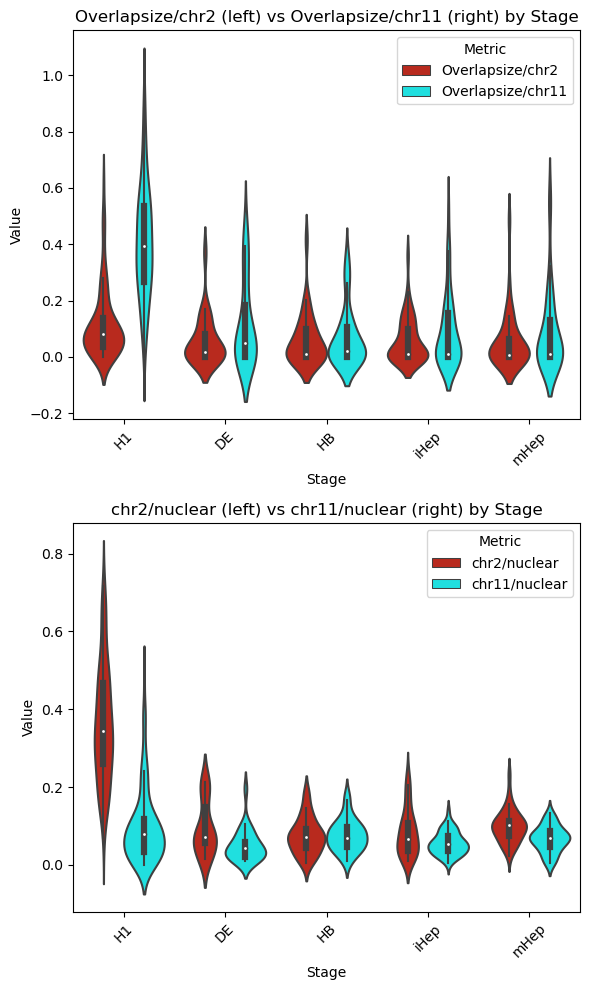

In [20]:
# Melt the DataFrame for the top pair of metrics
df_top = two_chromsomes_df.melt(
    id_vars=["Stage"],
    value_vars=["Overlapsize/chr2", "Overlapsize/chr11"],
    var_name="Metric",
    value_name="Value"
)

# Melt the DataFrame for the bottom pair of metrics
df_bottom = two_chromsomes_df.melt(
    id_vars=["Stage"],
    value_vars=["chr2/nuclear", "chr11/nuclear"],
    var_name="Metric",
    value_name="Value"
)

# Define custom palettes for the split violins:
# For the top plot, assign "Overlapsize/nuclear" (left) and "Overlapsize/chr11" (right)
palette_top = {
    "Overlapsize/chr2": "#D21404",  # left
    "Overlapsize/chr11": "cyan"         # right
}

# For the bottom plot, assign "chr11/nuclear" (left) and "chr2/nuclear" (right)
palette_bottom = {
    "chr2/nuclear": "#D21404",  # left
    "chr11/nuclear": "cyan"       # right
}

# Create a figure with 2 rows and 1 column (two subplots)
fig, axes = plt.subplots(2, 1, figsize=(6, 10))

# Top plot: Split violin for Overlapsize/nuclear (left) vs Overlapsize/chr11 (right)
sns.violinplot(
    data=df_top,
    x="Stage",
    y="Value",
    hue="Metric",
    hue_order=["Overlapsize/chr2", "Overlapsize/chr11"],
    palette=palette_top,
    ax=axes[0]
)
axes[0].set_title("Overlapsize/chr2 (left) vs Overlapsize/chr11 (right) by Stage")
axes[0].set_xlabel("Stage")
axes[0].set_ylabel("Value")
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title="Metric")

# Bottom plot: Split violin for chr11/nuclear (left) vs chr2/nuclear (right)
sns.violinplot(
    data=df_bottom,
    x="Stage",
    y="Value",
    hue="Metric",
    hue_order=["chr2/nuclear", "chr11/nuclear"],
    palette=palette_bottom,
    ax=axes[1]
)
axes[1].set_title("chr2/nuclear (left) vs chr11/nuclear (right) by Stage")
axes[1].set_xlabel("Stage")
axes[1].set_ylabel("Value")
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title="Metric")

plt.tight_layout()

# Save the plot as a PDF with dpi=200
output_path = "/home/xiangru.huo-umw/scHiC/scripts/plot2/Chromosome_intermingling2.pdf"
plt.savefig(output_path, dpi=200, format="pdf", bbox_inches="tight")
plt.show()


In [21]:
# Convert length of 'Stage' column in two_chromsomes_df into a DataFrame
stage_counts_df = two_chromsomes_df.groupby("Stage").size().reset_index(name="Count")
stage_counts_df

,Stage,Count
0,DE,25
1,H1,104
2,HB,31
3,iHep,47
4,mHep,36
